# Monitor de Vaca Muerta · Notebook 02: Limpieza
### Etapa 2: de los CSV del Gobierno a archivos listos para la app y el modelo

En el notebook 01 encontramos varios problemas en los datos. Acá explicamos **cada decisión de limpieza** y la comprobamos.

**Una diferencia importante con las Partes 1 y 2:** la limpieza no vive en el notebook, sino en un script, `scripts/procesar.py`.
¿Por qué? Porque la app se va a actualizar sola todos los meses (Etapa 4) y ahí no hay nadie que abra un notebook:
GitHub Actions va a correr `descargar.py` y después `procesar.py`. Este notebook **usa las mismas funciones del script**,
así lo que se explica acá es exactamente lo que corre en automático.

**Qué genera** (en `datos/procesados/`, en formato **Parquet**):

| Archivo | Una fila por | Para qué |
|---|---|---|
| `produccion_pozo_mes.parquet` | pozo y mes | Base limpia completa |
| `resumen_mensual.parquet` | mes | Página *Resumen* y *Evolución* de la app |
| `empresas_mensual.parquet` | mes y empresa | Página *Empresas* |
| `pozos.parquet` | pozo | Página *Mapa* |
| `tabla_modelo.parquet` | pozo con fractura y 12 meses de producción | Modelo de ML (Etapa 5) |
| `diseno_anual.parquet` | año de fractura | Conclusiones del *Inicio*: largo de rama y etapas típicas |

> **¿Qué es Parquet?** Un formato de archivo para tablas, como el CSV, pero comprimido y que guarda el tipo de cada columna
> (fechas, números, textos). Los 150 MB del CSV original quedan en ~3 MB, y pandas lo lee mucho más rápido.

## 0. Preparación

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sys.path.append(str(Path("..") / "scripts"))   # para poder importar procesar.py
import procesar as pr

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "grid.color": "#e6e6e3"})
AZUL, GRIS, TEXTO = "#2a78d6", "#9a9994", "#52514e"
CARPETA_GRAF = Path("..") / "graficos"

## 1. Producción

`cargar_produccion()` hace cuatro cosas:
1. Verifica que estén todas las columnas esperadas. Si el Gobierno cambia el formato, el script se frena con un mensaje claro.
2. Se queda con la **formación Vaca Muerta**.
3. Pasa a 0 cualquier producción negativa (no tiene sentido físico).
4. Agrupa las empresas por **grupo empresario** (ver 1.1).

In [2]:
prod = pr.cargar_produccion()
print(f"{len(prod):,} filas · {prod['idpozo'].nunique():,} pozos · {prod['fecha'].min():%m/%Y} a {prod['fecha'].max():%m/%Y}")
prod.head(3)

219,848 filas · 3,417 pozos · 01/2006 a 08/2026


,idempresa,empresa,idpozo,sigla,prod_pet,prod_gas,prod_agua,tef,areayacimiento,provincia,coordenadax,coordenaday,tipopozo,tipoestado,sub_tipo_recurso,fecha,grupo
318265,PEL,PETROLERA ENTRE LOMAS S.A.,3640,PPC.Nq.EC-4,0.000,0.000,0.000,0.00000,EL CARACOL,Neuquén,-68.45239,-37.95417,Petrolífero,Extracción Efectiva,SHALE,2006-02-01,Petrolera Entre Lomas
318284,PEL,PETROLERA ENTRE LOMAS S.A.,3640,PPC.Nq.EC-4,30.808,1.731,30.570,10.41667,EL CARACOL,Neuquén,-68.45239,-37.95417,Petrolífero,Extracción Efectiva,SHALE,2006-03-01,Petrolera Entre Lomas
318385,PEL,PETROLERA ENTRE LOMAS S.A.,3640,PPC.Nq.EC-4,76.609,3.713,46.479,30.00000,EL CARACOL,Neuquén,-68.45239,-37.95417,Petrolífero,Extracción Efectiva,SHALE,2006-04-01,Petrolera Entre Lomas


### 1.1 Empresas con más de un nombre

En el notebook 01 vimos a Pluspetrol dos veces. Revisando el código `idempresa` aparecen más casos: la misma empresa
registrada con distintas razones sociales o sucursales, o empresas que fueron compradas por otra.
Las juntamos en un **grupo** con el diccionario `GRUPOS` del script.

In [3]:
unificadas = (prod.groupby(["grupo", "empresa"]).size().rename("filas").reset_index()
                  .groupby("grupo").filter(lambda g: len(g) > 1))
unificadas

,grupo,empresa,filas
14,GeoPark,GEOPARK ARGENTINA LTD. (SUCURSAL ARGENTINA),45
15,GeoPark,GEOPARK ARGENTINA S.A.,108
22,Pampa Energía,PAMPA ENERGIA S.A.,2454
23,Pampa Energía,PETROBRAS ARGENTINA S.A.,234
24,Pan American Energy,PAN AMERICAN ENERGY (SUCURSAL ARGENTINA) LLC,581
25,Pan American Energy,PAN AMERICAN ENERGY SL,10198
32,Pluspetrol,PLUSPETROL CUENCA NEUQUINA S.R.L.,859
33,Pluspetrol,PLUSPETROL S.A.,6404
41,Vista,VISTA ENERGY ARGENTINA SAU,8351
42,Vista,VISTA OIL & GAS ARGENTINA SAU,1195


**Decisiones:**
- **Vista**, **Pluspetrol**, **Pan American**, **GeoPark** y **Wintershall**: son la misma empresa con distintos nombres legales.
- **YSUR** se suma a **YPF** porque es una subsidiaria suya.
- **Petrobras Argentina** se suma a **Pampa Energía**, que la compró en 2016.

Con esto el ranking cambia: Pluspetrol pasa a ser la **3.ª productora** (9%), algo que con los nombres sueltos no se veía.

In [4]:
emp = pr.empresas_mensual(prod)
ult12 = emp[emp["fecha"] > emp["fecha"].max() - pd.DateOffset(months=12)]
ranking = ult12.groupby("grupo")["prod_pet"].sum().sort_values(ascending=False)
(ranking / ranking.sum() * 100).head(8).round(1).to_frame("% del petróleo (últimos 12 meses)")

,% del petróleo (últimos 12 meses)
grupo,
YPF,52.5
Vista,12.7
Pluspetrol,9.0
Shell,5.9
Pan American Energy,5.2
Chevron,3.5
Tecpetrol,3.2
Pampa Energía,3.1


### 1.2 Pozos que cambiaron de operador

Algunos pozos pasan de una empresa a otra (por ventas de áreas). Para no mezclar:
- En **`empresas_mensual`** cada mes cuenta para la empresa que operaba **ese** mes.
- En **`pozos`** (el mapa) mostramos el operador **actual** (el último).

In [5]:
cambios = prod.groupby("idpozo")["grupo"].nunique()
print(f"Pozos que cambiaron de grupo empresario: {(cambios > 1).sum()} de {len(cambios):,}")

Pozos que cambiaron de grupo empresario: 217 de 3,417


## 2. Fracturas

`cargar_fracturas()` deja afuera tres tipos de registros que no se pueden usar:

| Problema | Por qué se descarta |
|---|---|
| Rama horizontal de 0 m | Son pozos verticales o datos sin cargar: no se comparan con un pozo horizontal |
| Presión de 0 o mayor a 20.000 psi | Imposible: los equipos de fractura trabajan hasta ~15.000 psi |
| Agua inyectada = 0 | Una fractura sin agua es un registro incompleto |

Además, si un pozo se fracturó más de una vez, nos quedamos con la **primera** fractura: es la que define su producción inicial.

In [6]:
frac = pr.cargar_fracturas()
print(f"Pozos con fractura válida (una fila por pozo): {len(frac):,}")

   Fracturas de Vaca Muerta: 3,095 -> 2,624 después de sacar valores imposibles
Pozos con fractura válida (una fila por pozo): 2,612


> Aquí **sí** eliminamos filas, a diferencia de la Parte 1 donde rellenábamos nulos. La diferencia es que acá el valor no falta:
> está **mal**, y un modelo que aprenda de una rama de 0 m o de 200.000 psi aprendería algo falso.

## 3. La variable a predecir: petróleo del primer año

La industria compara pozos nuevos por su producción de los **primeros 12 meses**. `produccion_primer_anio()` la calcula así:
1. Busca el primer mes en que el pozo produjo algo (su "inicio").
2. Suma el petróleo y el gas de ese mes y los 11 siguientes (12 meses calendario).
3. **Solo cuenta pozos con 12 meses completos** de historia. Un pozo que arrancó hace 5 meses tendría un total incompleto.

Un ejemplo con un pozo cualquiera:

In [7]:
p12 = pr.produccion_primer_anio(prod)
ejemplo = p12.sort_values("pet_12m_m3").iloc[len(p12) // 2]   # un pozo "del medio"
print(f"Pozo {ejemplo['idpozo']}: empezó en {ejemplo['inicio']:%m/%Y} y produjo {ejemplo['pet_12m_m3']:,.0f} m³ de petróleo "
      f"en su primer año (≈ {ejemplo['pet_12m_m3'] * pr.M3_A_BARRILES / 1000:,.0f} mil barriles).")
print(f"Pozos con 12 meses completos: {len(p12):,}")

Pozo 159223: empezó en 04/2018 y produjo 20,289 m³ de petróleo en su primer año (≈ 128 mil barriles).
Pozos con 12 meses completos: 2,886


## 4. Tabla para el modelo

Unimos fracturas con el primer año de producción por `idpozo` y dejamos solo los **pozos petrolíferos**:
en el notebook 01 vimos que los pozos de gas aparecían con petróleo casi nulo y "ensuciaban" la relación.

In [8]:
pozos = pr.tabla_pozos(prod)
tabla = pr.tabla_modelo(prod, pozos, frac)
print(f"Pozos en la tabla del modelo: {len(tabla):,}")
tabla.describe().T[["count", "min", "50%", "max"]].round(0)

Pozos en la tabla del modelo: 1,559


,count,min,50%,max
idpozo,1559.0,137008.0,163945.0,166844.0
lon,1559.0,-69.0,-69.0,-68.0
lat,1559.0,-39.0,-38.0,-37.0
anio_fractura,1559.0,2011.0,2022.0,2025.0
longitud_rama_horizontal_m,1559.0,119.0,2538.0,4965.0
cantidad_fracturas,1559.0,3.0,40.0,99.0
arena_total_tn,1559.0,167.0,9275.0,20834.0
agua_inyectada_m3,1559.0,1616.0,56202.0,160827.0
presion_maxima_psi,1559.0,5947.0,11722.0,19792.0
potencia_equipos_fractura_hp,1559.0,2000.0,40000.0,236451.0


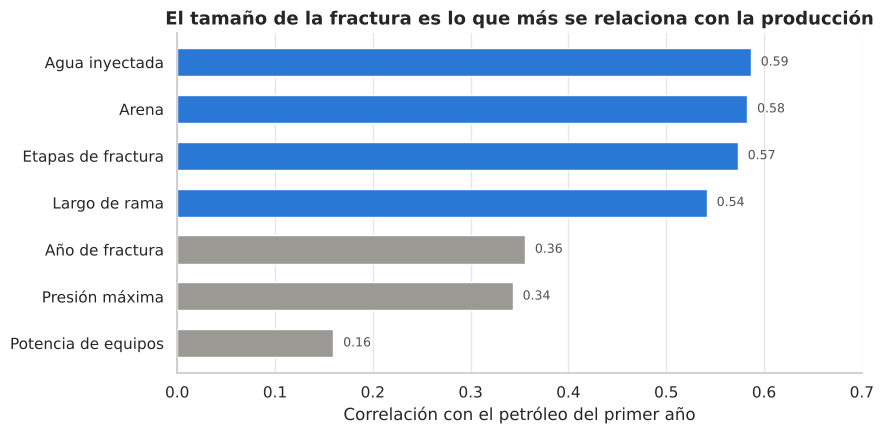

In [9]:
VARIABLES = {"longitud_rama_horizontal_m": "Largo de rama", "cantidad_fracturas": "Etapas de fractura",
             "arena_total_tn": "Arena", "agua_inyectada_m3": "Agua inyectada", "anio_fractura": "Año de fractura",
             "presion_maxima_psi": "Presión máxima", "potencia_equipos_fractura_hp": "Potencia de equipos"}
corr = tabla[list(VARIABLES)].corrwith(tabla["pet_12m_m3"]).rename(VARIABLES).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(corr.index, corr.values, color=[AZUL if v >= 0.5 else GRIS for v in corr.values], height=0.6)
for i, v in enumerate(corr.values):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=9, color=TEXTO)
ax.set_xlim(0, 0.7)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Correlación con el petróleo del primer año")
ax.set_title("El tamaño de la fractura es lo que más se relaciona con la producción")
plt.tight_layout()
plt.savefig(CARPETA_GRAF / "06_correlaciones_modelo.png", dpi=150)
plt.show()

**Lectura:**
- Con los datos limpios y solo pozos de petróleo, las correlaciones suben respecto del notebook 01 (el largo de rama pasa de 0,45 a ~0,54).
- **Agua, arena, etapas y largo de rama** están todas cerca de 0,55–0,6. Ojo: también están muy relacionadas **entre sí**
  (un pozo más largo lleva más etapas, más arena y más agua). El modelo de la Etapa 5 tendrá que lidiar con eso.
- La **potencia de los equipos** casi no se relaciona con la producción: probablemente no aporte al modelo.

## 5. Generar los archivos

Todo lo anterior se ejecuta junto con `python scripts/procesar.py`. Desde el notebook llamamos a la misma función:

In [10]:
import os
os.chdir("..")          # procesar.py trabaja desde la carpeta raíz de la app
pr.main()
os.chdir("notebooks")

1/3 Producción


   219,848 filas · 3,417 pozos · 01/2006 a 08/2026
2/3 Fracturas
   Fracturas de Vaca Muerta: 3,095 -> 2,624 después de sacar valores imposibles
3/3 Guardando Parquet


   produccion_pozo_mes.parquet   219,848 filas    3.3 MB
   resumen_mensual.parquet           248 filas    0.0 MB
   empresas_mensual.parquet        3,347 filas    0.1 MB
   pozos.parquet                   3,417 filas    0.2 MB
   tabla_modelo.parquet            1,559 filas    0.1 MB
   diseno_anual.parquet               16 filas    0.0 MB


Listo: {'ultimo_mes': '2026-08', 'pozos': 3417, 'pozos_modelo': 1559, 'pct_petroleo_vm': 96.5}


## 6. Resumen

- La base de Vaca Muerta limpia tiene **3.417 pozos** y llega a **agosto de 2026**; en Parquet pesa ~3 MB (contra 150 MB del CSV).
- Unificamos empresas por grupo: **Pluspetrol** aparece como 3.ª productora (9%).
- Descartamos fracturas imposibles y quedan **1.559 pozos petrolíferos** con fractura válida y 12 meses de producción para el modelo.

**Próximo paso (Etapa 3):** la app en Streamlit, que lee estos Parquet.